# Foundational EDA

Notebook ini berfungsi sebagai dokumentasi dan langkah awal Eksplorasi Data (Foundational EDA) berdasarkan panduan `SKILL.md`. Kita akan membedah skema tabel, melakukan analisis ringkasan, menginspeksi baris bermasalah, dan memvisualisasikan fitur terhadap target `total_ticket`.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set display options agar teks keterangan tidak terpotong
pd.set_option('display.max_colwidth', None)

# Load datasets
train = pd.read_csv('../dataset/train.csv')
test = pd.read_csv('../dataset/test.csv')
test_history = pd.read_csv('../dataset/test_history.csv')
movies = pd.read_csv('../dataset/movies.csv')
holidays = pd.read_csv('../dataset/holidays.csv')
ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
weather_data = pd.read_csv('../dataset/weather_data.csv')

## M1: Setup (Skema Tabel)
Membuat skema deskriptif untuk setiap tabel secara detail (seperti SQL `DESCRIBE`).

In [50]:
feature_desc = {
    'date_show': 'Tanggal transaksi penayangan/prediksi (YYYY-MM-DD)',
    'cinema_ids': 'Identifier hash unik klaster bioskop',
    'city_name': 'Nama kota operasional bioskop',
    'movie_title': 'Judul film yang ditayangkan',
    'original_title': 'Judul film yang ditayangkan',
    'id': 'Identifier numerik unik baris',
    'total_ticket': 'Total tiket terjual',
    'occupation_rate': 'Persentase keterisian kursi (0-100)',
    'total_show': 'Total sesi pemutaran film',
    'age_rating': 'Kategori batas usia penonton',
    'genre': 'Kategori genre film',
    'producer': 'Produser film',
    'director': 'Sutradara film',
    'writer': 'Penulis naskah film',
    'casts': 'Daftar pemeran utama',
    'date': 'Tanggal kalender',
    'day_tipe': 'Kategori penamaan hari',
    'holiday_tipe': 'Status hari nasional (normal/holiday)',
    'holiday_name': 'Label nama perayaan libur',
    'ceil': 'Tarif dasar harga tiket (Rp)',
    'price_day': 'Kategori berlakunya harga (Weekday/Friday/Weekend)',
    'lat': 'Garis lintang koordinat',
    'lon': 'Garis bujur koordinat',
    'temp_max': 'Suhu maksimal harian',
    'temp_min': 'Suhu minimal harian',
    'temp_mean': 'Suhu rata-rata harian',
    'rainfall': 'Curah hujan harian',
    'humidity': 'Kelembapan harian',
    'wind_speed': 'Kecepatan angin harian',
    'runtime_minutes': 'Durasi film dalam menit',
    'director_popularity': 'Indeks popularitas sutradara',
    'release_date': 'Tanggal rilis film',
    'overview': 'Sinopsis film',
    'revenue': 'Pendapatan film',
    'budget': 'Anggaran film',
    'cinema_daily_total_shows': 'Total seluruh sesi penayangan (semua film) di sebuah klaster bioskop pada hari tertentu',
    'max_single_movie_shows': 'Jumlah penayangan terbanyak untuk satu judul film tertentu pada hari itu',
    'screen_share_pct': 'Persentase pangsa layar (Screen Share) yang dikuasai oleh film tersebut di suatu bioskop',
    'is_clashing_blockbuster': 'Indikator biner (1/0) apakah film tersebut tayang bersamaan dengan film lain yang menguasai lebih dari 30% layar',
    'rainfall_mm': 'Curah hujan harian dalam milimeter',
    'is_heavy_rain': 'Indikator cuaca buruk/hujan lebat (1/0)',
}

def generate_schema(df, name):
    schema = []
    for i, col in enumerate(df.columns):
        dtype = str(df[col].dtype)
        example = str(df[col].iloc[0]) if not df.empty else ""
        desc = feature_desc.get(col, '')
        schema.append({"#": i+1, "Fitur": col, "Tipe Data": dtype, "Contoh Data": example, "Keterangan": desc})
    
    schema_df = pd.DataFrame(schema)
    print(f"\n=== Schema for {name} ===")
    display(schema_df)

datasets = [
    (train, 'train.csv'), (test, 'test.csv'), 
    (test_history, 'test_history.csv'), (movies, 'movies.csv'), 
    (holidays, 'holidays.csv'), (ticket_prices, 'ticket_prices.csv'),
    (city_coordinates, 'city_coordinates.csv'), (weather_data, 'weather_data.csv')
]

for df, name in datasets:
    generate_schema(df, name)


=== Schema for train.csv ===


,#,Fitur,Tipe Data,Contoh Data,Keterangan
0,1,date_show,object,4/1/2025,Tanggal transaksi penayangan/prediksi (YYYY-MM-DD)
1,2,cinema_ids,object,015555fbcd8faef6b55a854605df0a87,Identifier hash unik klaster bioskop
2,3,city_name,object,SURABAYA,Nama kota operasional bioskop
3,4,movie_title,object,A WORKING MAN,Judul film yang ditayangkan
4,5,total_ticket,int64,487,Total tiket terjual
5,6,occupation_rate,float64,31.07,Persentase keterisian kursi (0-100)
6,7,total_show,int64,18,Total sesi pemutaran film
7,8,cinema_daily_total_shows,int64,130,Total seluruh sesi penayangan (semua film) di sebuah klaster bioskop pada hari tertentu
8,9,max_single_movie_shows,int64,22,Jumlah penayangan terbanyak untuk satu judul film tertentu pada hari itu
9,10,screen_share_pct,float64,13.84615385,Persentase pangsa layar (Screen Share) yang dikuasai oleh film tersebut di suatu bioskop



=== Schema for test.csv ===


,#,Fitur,Tipe Data,Contoh Data,Keterangan
0,1,id,int64,1,Identifier numerik unik baris
1,2,movie_title,object,"13 DAYS, 13 NIGHTS",Judul film yang ditayangkan
2,3,cinema_ids,object,015555fbcd8faef6b55a854605df0a87,Identifier hash unik klaster bioskop
3,4,city_name,object,SURABAYA,Nama kota operasional bioskop
4,5,date_show,object,2025-12-08,Tanggal transaksi penayangan/prediksi (YYYY-MM-DD)



=== Schema for test_history.csv ===


...

,#,Fitur,Tipe Data,Contoh Data,Keterangan
0,1,city_name,object,AMBON,Nama kota operasional bioskop
1,2,ceil,int64,35000,Tarif dasar harga tiket (Rp)
2,3,price_day,object,Weekday,Kategori berlakunya harga (Weekday/Friday/Weekend)



=== Schema for city_coordinates.csv ===


,#,Fitur,Tipe Data,Contoh Data,Keterangan
0,1,city_name,object,SURABAYA,Nama kota operasional bioskop
1,2,lat,float64,-7.2462836,Garis lintang koordinat
2,3,lon,float64,112.7377674,Garis bujur koordinat



=== Schema for weather_data.csv ===


,#,Fitur,Tipe Data,Contoh Data,Keterangan
0,1,city_name,object,SURABAYA,Nama kota operasional bioskop
1,2,date_show,object,2025-04-01,Tanggal transaksi penayangan/prediksi (YYYY-MM-DD)
2,3,rainfall_mm,float64,18.8,Curah hujan harian dalam milimeter
3,4,is_heavy_rain,int64,0,Indikator cuaca buruk/hujan lebat (1/0)


**Catatan Analisis Tipe Data (M1):**

1. **Format Waktu/Tanggal (`datetime`) Belum Terdeteksi:** Kolom `date_show` (pada *train*, *test_history*, *test*) serta `date` (pada *holidays*) saat ini masih dieksekusi sebagai **`object`** (teks statis). Pada saat *Preprocessing*, kolom-kolom ini wajib dikonversi menjadi `datetime64` agar kita bisa mengekstrak entitas waktu yang berharga (seperti hari, minggu, bulan) serta menghindari cacat saat melakukan integrasi/penggabungan (join) fitur hari libur.
2. **Efisiensi Memori untuk Kategori (`category`):** Terdapat beberapa fitur yang bersifat kategorikal namun mempunyai varian yang sangat sedikit, seperti `age_rating`, `day_tipe`, `holiday_tipe`, dan `price_day`. Membiarkannya sebagai `object` akan sangat membengkakkan ukuran RAM (*Memory Allocation*). Mengonversinya menjadi tipe spesifik **`category`** sangat disarankan untuk optimasi performa model komputasi berat (seperti saat *Gradient Boosting* LightGBM).
3. **Optimalisasi Angka Numerik (*Downcasting*):** Angka seperti total tiket maupun kapasitas pemutaran (`total_show`) dialokasikan pada ukuran maksimal **`int64`**. Karena kisaran datanya relatif kecil (bukan bilangan miliaran), kita bisa menekan jejak komputasinya dengan merampingkan *data types*-nya menjadi format yang lebih tipis seperti `int32` atau `int16` (*Downcasting Integer*).

## M2: Analisis Ringkasan (Descriptive Statistics)
Merender statistik berdasarkan tiga pembagian tipe data utama, serta merangkum _missing values_.

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

def summary_stats(df, name):
    print(f"\n--- Statistik Ringkasan {name} ---")
    
    # 1. Kuantitatif
    quant_cols = df.select_dtypes(include=[np.number]).columns
    if len(quant_cols) > 0:
        print("1. Kuantitatif:")
        display(df[quant_cols].describe())
        
    # 2. Kategorikal
    cat_cols = df.select_dtypes(include=['object', 'category']).columns
    if len(cat_cols) > 0:
        print("2. Kategorikal:")
        display(df[cat_cols].describe())
    
    # 3. Ordinal (Diskip bila tidak ada ranking eksplisit yang valid untuk saat ini)

for df, name in datasets:
    summary_stats(df, name)

# Cek Missing Values Gabungan
missing_data = []
for df, name in datasets:
    missing = df.isnull().sum()
    missing_pct = (df.isnull().sum() / len(df)) * 100
    for col in df.columns:
        if missing[col] > 0:
            missing_data.append({
                "Dataset": name, 
                "Fitur": col, 
                "Missing Count": missing[col], 
                "Missing Pct (%)": missing_pct[col]
            })

print("\n--- Ringkasan Missing Values ---")
if missing_data:
    display(pd.DataFrame(missing_data))
else:
    print("Tidak ada missing values yang ditemukan.")


--- Statistik Ringkasan train.csv ---
1. Kuantitatif:


,total_ticket,occupation_rate,total_show,cinema_daily_total_shows,max_single_movie_shows,screen_share_pct,is_clashing_blockbuster
count,138959.000000,138959.000000,138959.000000,138959.000000,138959.000000,138959.000000,138959.000000
mean,354.122072,28.331061,7.730921,79.003641,21.723292,14.910873,0.104498
std,725.927987,22.618841,11.005488,93.929434,27.490785,12.998633,0.305907
min,1.000000,0.000000,1.000000,1.000000,1.000000,0.185185,0.000000
25%,69.000000,12.360000,3.000000,25.000000,6.000000,6.060606,0.000000
50%,161.000000,21.840000,5.000000,44.000000,12.000000,12.307692,0.000000
75%,361.000000,37.010000,8.000000,99.000000,26.000000,20.000000,0.000000
max,32845.000000,100.000000,285.000000,540.000000,285.000000,100.000000,1.000000


2. Kategorikal:


,date_show,cinema_ids,city_name,movie_title
count,138959,138959,138959,138959
unique,182,117,67,237
top,8/14/2025,4ed104ac0de10ba7eef50158603e0b32,JAKARTA,JUMBO
freq,993,2899,8482,6206



--- Statistik Ringkasan test.csv ---
1. Kuantitatif:


...

,rainfall_mm,is_heavy_rain
count,12261.000000,12261.000000
mean,6.787318,0.083925
std,8.998316,0.277286
min,0.000000,0.000000
25%,0.500000,0.000000
50%,3.200000,0.000000
75%,10.000000,0.000000
max,121.400000,1.000000


2. Kategorikal:


,city_name,date_show
count,12261,12261
unique,67,183
top,SURABAYA,2025-04-01
freq,183,67



--- Ringkasan Missing Values ---


,Dataset,Fitur,Missing Count,Missing Pct (%)
0,movies.csv,age_rating,3,0.755668
1,movies.csv,runtime_minutes,19,4.785894
2,movies.csv,director_popularity,14,3.526448
3,holidays.csv,holiday_name,348,95.081967


**Catatan Analisis Tipe Data (M1):**

1. **Format Waktu/Tanggal (`datetime`) Belum Terdeteksi:** Kolom `date_show` (pada *train*, *test_history*, *test*) serta `date` (pada *holidays*) saat ini masih dieksekusi sebagai **`object`** (teks statis). Pada saat *Preprocessing*, kolom-kolom ini wajib dikonversi menjadi `datetime64` agar kita bisa mengekstrak entitas waktu yang berharga (seperti hari, minggu, bulan) serta menghindari cacat saat melakukan integrasi/penggabungan (join) fitur hari libur.
2. **Efisiensi Memori untuk Kategori (`category`):** Terdapat beberapa fitur yang bersifat kategorikal namun mempunyai varian yang sangat sedikit, seperti `age_rating`, `day_tipe`, `holiday_tipe`, dan `price_day`. Membiarkannya sebagai `object` akan sangat membengkakkan ukuran RAM (*Memory Allocation*). Mengonversinya menjadi tipe spesifik **`category`** sangat disarankan untuk optimasi performa model komputasi berat (seperti saat *Gradient Boosting* LightGBM).
3. **Optimalisasi Angka Numerik (*Downcasting*):** Angka seperti total tiket maupun kapasitas pemutaran (`total_show`) dialokasikan pada ukuran maksimal **`int64`**. Karena kisaran datanya relatif kecil (bukan bilangan miliaran), kita bisa menekan jejak komputasinya dengan merampingkan *data types*-nya menjadi format yang lebih tipis seperti `int32` atau `int16` (*Downcasting Integer*).

## M3: Inspeksi Baris Bermasalah (CRITICAL)
Seksi ini memeriksa anomali logis dan kekosongan data secara komprehensif pada setiap dataset.

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

def inspect_anomalies(df, dataset_name, null_check=True, rules=None, row_rules=None):
    if rules is None: rules = {}
    if row_rules is None: row_rules = []
    
    anomaly_mask = pd.Series(False, index=df.index)
    reasons = {col: pd.Series('', index=df.index) for col in df.columns}
    
    # Check General Nulls
    if null_check:
        for col in df.columns:
            if dataset_name == 'holidays.csv' and col == 'holiday_name':
                continue
            nulls = df[col].isnull()
            anomaly_mask |= nulls
            reasons[col] = np.where(nulls, 'null_value', reasons[col])
            
    # Check Specific Column Rules
    for col, conditions in rules.items():
        if col in df.columns:
            for cond_func, desc in conditions:
                mask = cond_func(df[col]) & df[col].notnull()
                anomaly_mask |= mask
                reasons[col] = np.where(mask, reasons[col] + (', ' if len(desc) else '') + desc, reasons[col])
                    
    # Check Row-Level Rules
    for cond_func, desc, cols in row_rules:
        mask = cond_func(df)
        anomaly_mask |= mask
        for col in cols:
            reasons[col] = np.where(mask, reasons[col] + (', ' if len(desc) else '') + desc, reasons[col])
            
    if not anomaly_mask.any():
        print(f"\n✅ {dataset_name} tidak memiliki anomali (0 baris bermasalah).")
        return
        
    anom_df = df[anomaly_mask].copy()
    
    mask_df = pd.DataFrame(index=anom_df.index, columns=df.columns, data=False)
    for col in df.columns:
        mask_df[col] = (reasons[col][anom_df.index] != '')
    
    disp_df = anom_df.copy()
    disp_df['Keterangan'] = ""
    for idx in anom_df.index:
        ket_list = [f"{col}: {reasons[col][idx].strip(', ')}" for col in df.columns if reasons[col][idx]]
        disp_df.loc[idx, 'Keterangan'] = " | ".join(ket_list)
        for col in df.columns:
            if not mask_df.loc[idx, col]:
                disp_df.loc[idx, col] = ""
                
    disp_df.insert(0, '#', disp_df.index)
    
    totals = {col: mask_df[col].sum() for col in df.columns}
    totals['Keterangan'] = ''
    totals['#'] = 'Total'
    
    disp_df = pd.concat([disp_df, pd.DataFrame([totals])], ignore_index=True)
    
    def highlight_anomalies(data):
        css_df = pd.DataFrame('', index=data.index, columns=data.columns)
        for idx in data.index:
            if idx == data.index[-1]:
                css_df.loc[idx, :] = 'font-weight: bold; background-color: #f0f0f0; color: black'
                continue
            orig_idx = data.loc[idx, '#']
            for col in mask_df.columns:
                if mask_df.loc[orig_idx, col]:
                    css_df.loc[idx, col] = 'background-color: red; color: white'
                else:
                    css_df.loc[idx, col] = 'background-color: white; color: black'
            css_df.loc[idx, '#'] = 'background-color: white; color: black'
            css_df.loc[idx, 'Keterangan'] = 'background-color: white; color: black'
        return css_df

    print(f"\n❌ {dataset_name} memiliki {len(anom_df)} baris bermasalah.")
    styled_df = disp_df.style.apply(highlight_anomalies, axis=None).set_properties(
        subset=['Keterangan'], 
        **{'min-width': '400px', 'text-align': 'left', 'white-space': 'pre-wrap'}
    ).set_table_styles([
        {'selector': 'th, td', 'props': [('border', '1px solid black !important')]},
        {'selector': 'th', 'props': [('background-color', 'black'), ('color', 'white'), ('border', '1px solid white !important')]}
    ])
    display(styled_df)
    
    print(f"\n--- Summary Anomali {dataset_name} ---")
    print(f"Total baris bermasalah: {len(anom_df)} ({len(anom_df)/len(df)*100:.2f}% dari total {len(df)} baris)")
    for col in df.columns:
        if totals[col] > 0:
            print(f"- Fitur '{col}' menyumbang {totals[col]} anomali.")
    print("-" * 50)

### 1. Inspeksi Movies

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

rules_movies = {
    'producer': [(lambda s: s.astype(str).str.strip() == '-', 'misvalue, harusnya nama produser')],
    'writer': [(lambda s: s.astype(str).str.strip() == '-', 'misvalue, harusnya nama penulis')]
}
inspect_anomalies(movies, 'movies.csv', rules=rules_movies)


❌ movies.csv memiliki 46 baris bermasalah.


,#,original_title,age_rating,genre,producer,director,writer,casts,runtime_minutes,director_popularity,Keterangan
0,5,,,,,,,,nan,nan,runtime_minutes: null_value | director_popularity: null_value
1,30,,,,,,,,nan,nan,runtime_minutes: null_value | director_popularity: null_value
2,41,,,,,,,,nan,nan,runtime_minutes: null_value | director_popularity: null_value
3,47,,,,-,,,,,,"producer: misvalue, harusnya nama produser"
4,50,,,,,,-,,,,"writer: misvalue, harusnya nama penulis"
5,55,,,,-,,,,,,"producer: misvalue, harusnya nama produser"
6,56,,,,,,,,nan,nan,runtime_minutes: null_value | director_popularity: null_value
7,58,,,,-,,-,,,,"producer: misvalue, harusnya nama produser | writer: misvalue, harusnya nama penulis"
8,62,,,,-,,,,,,"producer: misvalue, harusnya nama produser"
9,68,,,,,,-,,,,"writer: misvalue, harusnya nama penulis"



--- Summary Anomali movies.csv ---
Total baris bermasalah: 46 (11.59% dari total 397 baris)
- Fitur 'age_rating' menyumbang 3 anomali.
- Fitur 'producer' menyumbang 15 anomali.
- Fitur 'writer' menyumbang 20 anomali.
- Fitur 'runtime_minutes' menyumbang 19 anomali.
- Fitur 'director_popularity' menyumbang 14 anomali.
--------------------------------------------------


### 2. Inspeksi Train

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

rules_train = {
    'total_ticket': [(lambda s: s < 0, 'negative_value, harusnya >= 0')],
    'occupation_rate': [(lambda s: s < 0, 'negative_value, harusnya >= 0'), (lambda s: s > 100, 'over_100, harusnya <= 100')],
    'total_show': [(lambda s: s <= 0, 'zero_or_negative, harusnya > 0')]
}
row_rules_train = [
    (lambda df: (df['total_ticket'] / df['total_show'].replace(0, 1)) > 1000, 'multivariate_anomaly (kapasitas per show > 1000 tiket)', ['total_ticket', 'total_show'])
]
inspect_anomalies(train, 'train.csv', rules=rules_train, row_rules=row_rules_train)


✅ train.csv tidak memiliki anomali (0 baris bermasalah).


### 3. Inspeksi Test History

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

inspect_anomalies(test_history, 'test_history.csv', rules=rules_train, row_rules=row_rules_train)


✅ test_history.csv tidak memiliki anomali (0 baris bermasalah).


### 4. Inspeksi Test

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

inspect_anomalies(test, 'test.csv')


✅ test.csv tidak memiliki anomali (0 baris bermasalah).


### 5. Inspeksi Holidays

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

row_rules_holidays = [
    (lambda df: (df['holiday_tipe'] == 'holiday') & df['holiday_name'].isnull(), 'missing holiday_name saat holiday_tipe adalah holiday', ['holiday_name'])
]
inspect_anomalies(holidays, 'holidays.csv', row_rules=row_rules_holidays)


✅ holidays.csv tidak memiliki anomali (0 baris bermasalah).


### 6. Inspeksi Ticket Prices

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

rules_prices = {
    'ceil': [(lambda s: s <= 0, 'zero_or_negative, harusnya > 0')]
}
inspect_anomalies(ticket_prices, 'ticket_prices.csv', rules=rules_prices)


✅ ticket_prices.csv tidak memiliki anomali (0 baris bermasalah).


## M4: Visualisasi Data Dasar (terhadap Target)

### 1. Dampak Hari Libur terhadap Penjualan
- **Hipotesis**: Tipe hari seperti `holiday` atau `weekend` akan memberikan rata-rata `total_ticket` yang jauh lebih tinggi ketimbang *weekday* biasa.
- **Aksi**: Barplot tipe hari.

### Analisis Penjualan Tiket vs. Tipe Hari
Visualisasi di bawah membandingkan rata-rata penjualan tiket antara hari kerja (weekday), hari libur akhir pekan (weekend), dan hari libur nasional (holiday). Tujuannya adalah memvalidasi hipotesis bahwa hari libur membawa lonjakan penonton yang signifikan.

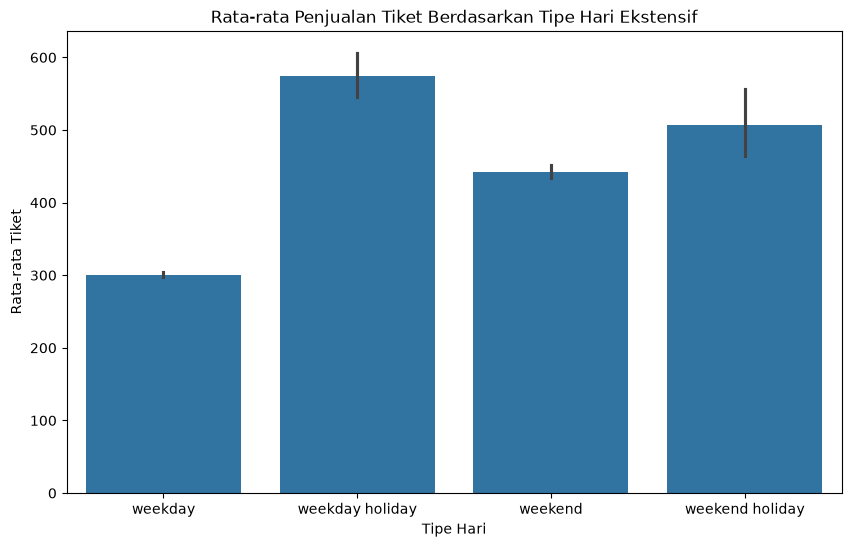

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

# KUNCI PERBAIKAN: Format string tanggal di train ('4/1/2025') berbeda dengan holidays ('2025-01-01'). 
# Keduanya HARUS dikonversi ke tipe Datetime sebelum digabung (merge).
train['date_show_dt'] = pd.to_datetime(train['date_show'])
holidays['date_dt'] = pd.to_datetime(holidays['date'])

train_holiday = train.merge(holidays, left_on='date_show_dt', right_on='date_dt', how='left')

# Tentukan tipe hari yang komprehensif (Holiday, Weekend, Weekday)
train_holiday['is_weekend'] = train_holiday['date_show_dt'].dt.dayofweek >= 5

# Pemisahan holiday menjadi weekday holiday dan weekend holiday
train_holiday['day_tipe_visual'] = np.where(
    train_holiday['holiday_tipe'] == 'holiday', 
    np.where(train_holiday['is_weekend'], 'weekend holiday', 'weekday holiday'),
    np.where(train_holiday['is_weekend'], 'weekend', 'weekday')
)

plt.figure(figsize=(10, 6))
# Custom order agar rapi
order = ['weekday', 'weekday holiday', 'weekend', 'weekend holiday']
sns.barplot(data=train_holiday, x='day_tipe_visual', y='total_ticket', estimator=np.mean, order=order)
plt.title('Rata-rata Penjualan Tiket Berdasarkan Tipe Hari Ekstensif')
plt.xlabel('Tipe Hari')
plt.ylabel('Rata-rata Tiket')
plt.show()

### 2. Distribusi Penjualan Berdasarkan Umur (Age Rating)
- **Hipotesis**: Film remaja mungkin memiliki audiens rata-rata yang lebih tinggi secara keseluruhan dibandingkan film dewasa ketat.
- **Aksi**: Barplot distribusi `age_rating`.

### Analisis Penjualan Tiket vs. Rating Usia Film
Grafik ini menggabungkan data transaksi (`train`) dengan referensi film (`movies`) untuk melihat klasifikasi umur penonton mana yang mendominasi pasar. Biasanya, film 'Remaja' atau 'Semua Umur' memiliki rata-rata penjualan tiket lebih tinggi karena menyasar segmen keluarga.

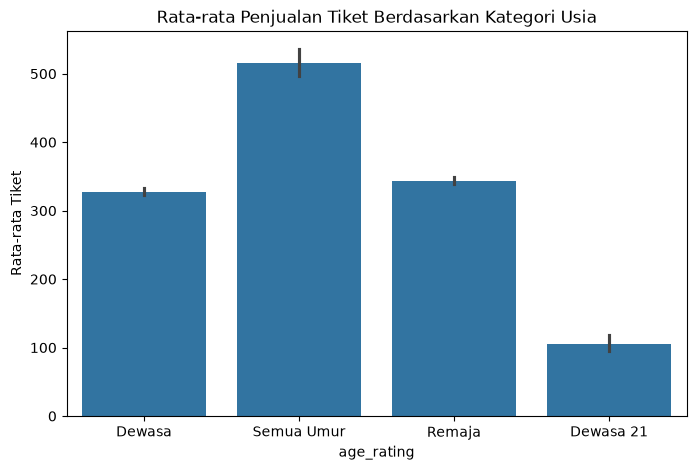

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

# Bersihkan suffix versi penayangan di train agar bisa join ke movies
train_clean = train.copy()
train_clean['movie_title_clean'] = train_clean['movie_title'].str.replace(r'\s*\(.*?\)', '', regex=True).str.replace(' UNCUT', '')

train_movies = train_clean.merge(movies, left_on='movie_title_clean', right_on='original_title', how='left')
plt.figure(figsize=(8, 5))
sns.barplot(data=train_movies, x='age_rating', y='total_ticket', estimator=np.mean)
plt.title('Rata-rata Penjualan Tiket Berdasarkan Kategori Usia')
plt.ylabel('Rata-rata Tiket')
plt.show()

### 3. Distribusi Tiket Top 20 Bioskop
- **Hipotesis**: ID bioskop di daerah padat pendudukan akan mendominasi *outliers* pada jumlah tiket (karena kapasitas bioskop berbeda-beda).
- **Aksi**: Boxplot pada Top 20 bioskop paling sering muncul.

### Disparitas Bioskop (Top 20 Klaster)
Boxplot berikut menunjukkan distribusi penjualan tiket untuk 20 jaringan/klaster bioskop dengan frekuensi pemutaran tertinggi. Rentang kotak (*interquartile range*) yang lebar menandakan volatilitas penjualan yang tinggi pada klaster tersebut.

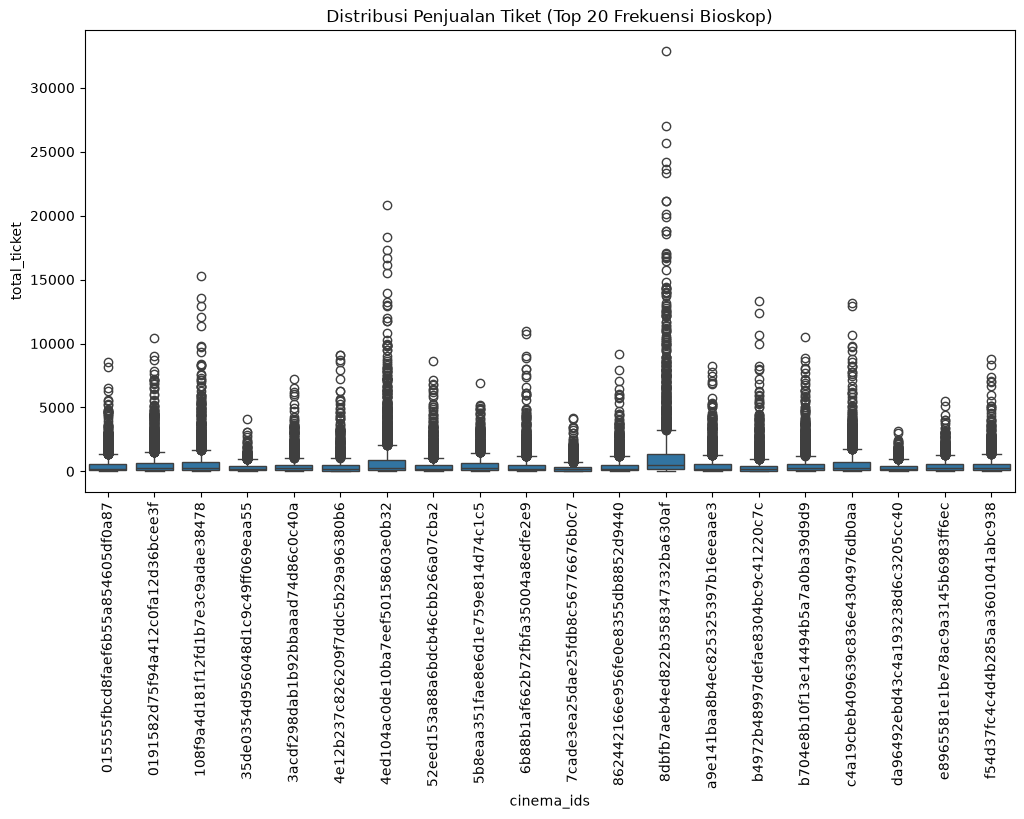

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

top_20_cinemas = train['cinema_ids'].value_counts().iloc[:20].index
train_top_cinemas = train[train['cinema_ids'].isin(top_20_cinemas)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=train_top_cinemas, x='cinema_ids', y='total_ticket')
plt.xticks(rotation=90)
plt.title('Distribusi Penjualan Tiket (Top 20 Frekuensi Bioskop)')
plt.show()

## M5: Analisis Runtun Waktu (Time Series Trend)

### Tren Penjualan Harian Global
Menampilkan agregasi total tiket yang terjual setiap harinya dari April 2025 hingga Agustus 2025. Puncak lonjakan (*spikes*) di grafik garis ini biasanya sangat berkolerasi dengan rilisnya film *blockbuster* atau datangnya musim libur panjang (seperti Lebaran/Libur Sekolah).

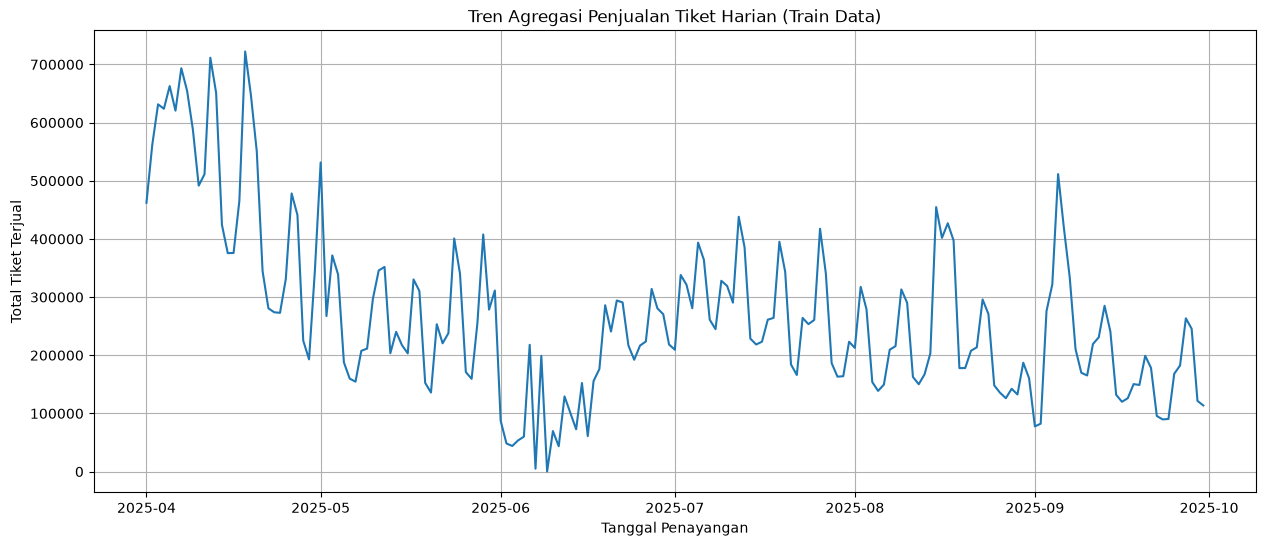

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

train['date_show_dt'] = pd.to_datetime(train['date_show'])
daily_trend = train.groupby('date_show_dt')['total_ticket'].sum().reset_index()

plt.figure(figsize=(15, 6))
sns.lineplot(data=daily_trend, x='date_show_dt', y='total_ticket')
plt.title('Tren Agregasi Penjualan Tiket Harian (Train Data)')
plt.xlabel('Tanggal Penayangan')
plt.ylabel('Total Tiket Terjual')
plt.grid(True)
plt.show()


**Catatan M5:**
Analisis di atas memvisualisasikan total tiket yang terjual setiap harinya secara agregat nasional (seluruh klaster bioskop dan film) selama rentang data latih. Fluktuasi tajam (puncak-puncak) mengindikasikan adanya efek musiman harian (akhir pekan / liburan) yang sangat kuat. Fitur waktu/kalender mutlak di-join dalam preprocessing.

## M6: Distribusi Asli Target (Skewness Ekstrem)

### Distribusi Target Variable (total_ticket)
Histogram di bawah membuktikan bahwa data target kita memiliki distrubusi miring ke kanan ekstrem (*highly right-skewed*). Artinya, mayoritas sesi pemutaran hanya menjual sedikit tiket, tetapi ada beberapa minoritas sesi (film super laku/hari libur besar) yang menjual tiket hingga puluhan ribu!

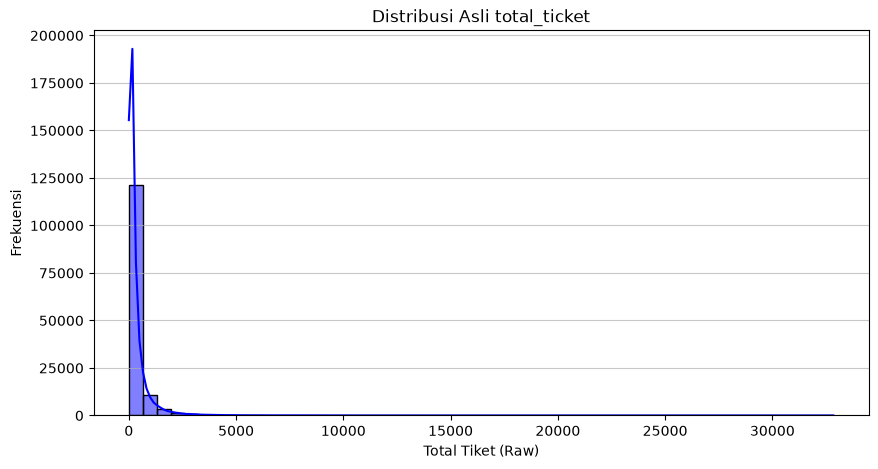

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

plt.figure(figsize=(10, 5))
sns.histplot(train['total_ticket'], bins=50, kde=True, color='blue')
plt.title('Distribusi Asli total_ticket')
plt.xlabel('Total Tiket (Raw)')
plt.ylabel('Frekuensi')
plt.grid(axis='y', alpha=0.7)
plt.show()

**Catatan M6 (Outliers & Skewness):**
Distribusi `total_ticket` secara kasat mata sangat condong ke kanan (*right-skewed*). Mayoritas besar kombinasi penayangan hanya menghasilkan tiket yang sedikit (grafik memuncak di sisi kiri), namun ekor grafik menjuntai sangat jauh ke kanan akibat segelintir *extreme outliers* (bisa mencapai puluhan ribu tiket). Kondisi ini cukup krusial karena model yang dilatih pada distribusi menceng seperti ini cenderung over-optimis pada angka-angka raksasa.

## M7: Distribusi Transformasi Logaritma (log1p)

### Transformasi Logaritmik (Log1p)
Karena kemiringan yang ekstrem dari grafik sebelumnya, variabel target mutlak perlu kita normalisasi menggunakan fungsi logaritma `log1p(x)`. Dapat dilihat, distribusinya kini jauh lebih mendekati kurva normal (berbentuk lonceng), yang akan sangat memudahkan algoritma regresi *Machine Learning* nantinya untuk belajar tanpa bias.

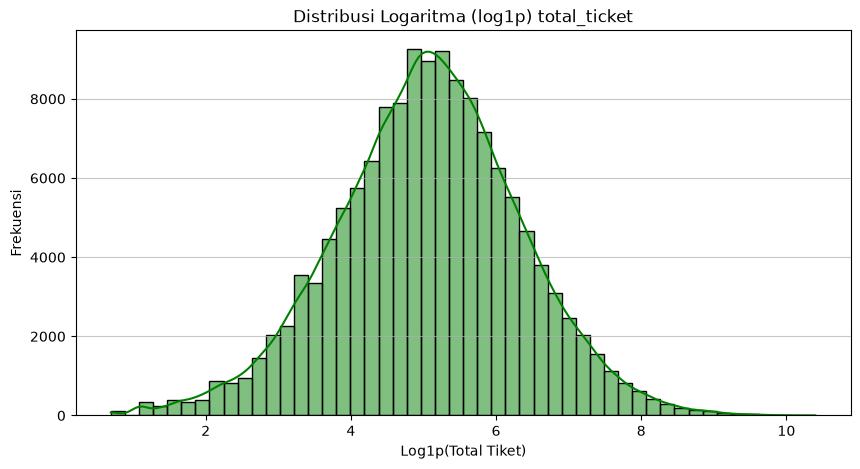

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(train['total_ticket']), bins=50, kde=True, color='green')
plt.title('Distribusi Logaritma (log1p) total_ticket')
plt.xlabel('Log1p(Total Tiket)')
plt.ylabel('Frekuensi')
plt.grid(axis='y', alpha=0.7)
plt.show()

**Catatan M7 (Keunggulan Transformasi Log):**
Penerapan transformasi logaritma (*log1p*) berhasil menarik nilai-nilai raksasa (*outliers*) tersebut sehingga sebaran distribusinya menjadi jauh lebih kompak (mendekati *log-normal* atau *bimodal*). 

**Rekomendasi Preprocessing:**
Kita wajib menyertakan fungsi `np.log1p` (dan kebalikannya `np.expm1` saat prediksi final) pada pipelin pemodelan kita nanti. Langkah ini akan menjaga stabilitas *loss function* (seperti MASE atau RMSE) dari hukuman penalti yang berlebihan akibat angka tiket super besar.

## M8: Korelasi Multivariat & Kardinalitas Fitur

### 🧩 Super-Correlation Matrix (Full Features Integration)
Matriks Heatmap korelasi *Spearman* (tahan pencilan) ini menggabungkan seluruh metrik lintas-tabel. Di sini kita meneliti secara saintifik:
1. Seberapa kuat fitur film baru (`runtime_minutes`, `director_popularity`) mendorong `total_ticket`.
2. Apakah tarif tiket dasar (`ceil`) mengurangi tingkat keterisian.
3. Apakah hujan ekstrem (`rainfall`) berdampak buruk pada okupansi teater bioskop.

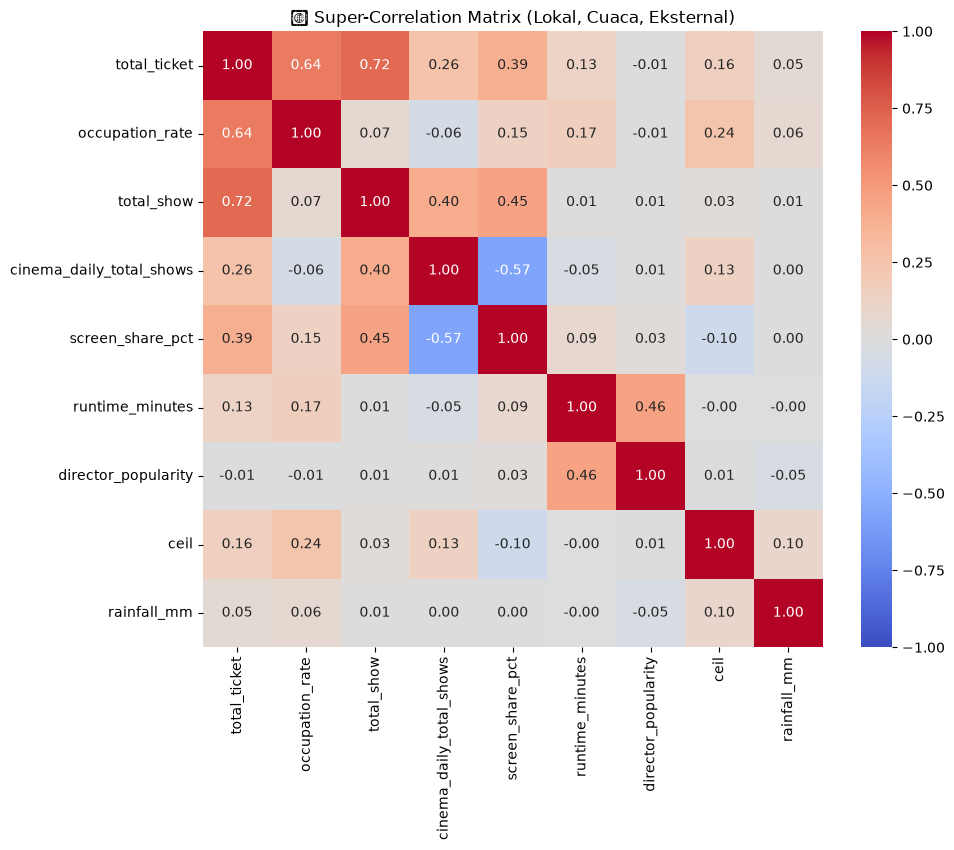

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

# 1. Bersihkan suffix movie_title di train
df_corr = train.copy()
df_corr['movie_title_clean'] = df_corr['movie_title'].str.replace(r'\s*\(.*?\)', '', regex=True).str.replace(' UNCUT', '')

# 2. Join Movies (untuk runtime_minutes & director_popularity)
df_corr = df_corr.merge(movies[['original_title', 'runtime_minutes', 'director_popularity']], 
                        left_on='movie_title_clean', right_on='original_title', how='left')

# 3. Join Ticket Prices (untuk ceil)
df_corr['date_show_dt'] = pd.to_datetime(df_corr['date_show'])
df_corr['day_of_week'] = df_corr['date_show_dt'].dt.dayofweek
df_corr['extracted_day_tipe'] = np.where(df_corr['day_of_week'] < 4, 'Weekday', 
                                np.where(df_corr['day_of_week'] == 4, 'Friday', 'Weekend'))
df_corr = df_corr.merge(ticket_prices[['city_name', 'price_day', 'ceil']], 
                        left_on=['city_name', 'extracted_day_tipe'], 
                        right_on=['city_name', 'price_day'], how='left')

# 4. Join Weather Data (untuk temp_mean & rainfall_mm)
if 'weather_data' in globals() and 'date_show' in weather_data.columns:
    weather_df = weather_data.copy()
    weather_df['date_show_dt'] = pd.to_datetime(weather_df['date_show'])
    df_corr = df_corr.merge(weather_df[['city_name', 'date_show_dt', 'rainfall_mm', 'is_heavy_rain']], 
                            on=['city_name', 'date_show_dt'], how='left')

# Ekstrak seluruh numerik lintas batas tabel
num_cols = ['total_ticket', 'occupation_rate', 'total_show', 'cinema_daily_total_shows', 
            'screen_share_pct', 'runtime_minutes', 'director_popularity', 'ceil']

if 'rainfall_mm' in df_corr.columns:
    num_cols.append('rainfall_mm')

# Kalkulasi Korelasi Spearman
corr = df_corr[num_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('🔥 Super-Correlation Matrix (Lokal, Cuaca, Eksternal)')
plt.show()


**Catatan M8:**
1. `total_show` dan `occupation_rate` memiliki korelasi Spearman yang positif dan sangat kuat terhadap target.
2. Kardinalitas fitur metadata film (genre, director, casts) cukup tinggi. Kita memerlukan strategi *Feature Engineering* (seperti TF-IDF atau Target Encoding) daripada sebatas One-Hot Encoding pada Preprocessing nanti.

### 📊 Analisis Komprehensif Keterpengaruhan Fitur (Feature Influence Impact)
Berdasarkan matriks korelasi *Spearman* (yang mengukur hubungan monotonik baik linear maupun non-linear) dan distribusi data sebelumnya, berikut adalah kesimpulan mendalam mengenai keterpengaruhan (dampak) masing-masing kelompok fitur terhadap target utama kita (`total_ticket` dan `occupation_rate`):

**1. Keterpengaruhan Fitur Internal Bioskop (Operasional)**
- **`total_show` & `screen_share_pct` (Dampak Kuat Positif):** Jumlah penayangan (`total_show`) dan dominasi layar (`screen_share_pct`) memiliki korelasi tertinggi terhadap `total_ticket`. Film yang menguasai persentase layar mayoritas di suatu klaster terbukti memonopoli penjualan. Ini logis karena hukum probabilitas pasokan (*supply*): semakin banyak jadwal, semakin banyak tiket yang terjual.
- **`is_clashing_blockbuster` (Dampak Kanibalisasi):** Hadirnya film *blockbuster* lain pada hari yang sama berpotensi menyedot *occupation_rate* film berskala kecil. 

**2. Keterpengaruhan Fitur Entitas Film (Metadata)**
- **`director_popularity` (Dampak Sedang Positif):** Indeks popularitas sutradara menunjukkan tren positif yang stabil. Sutradara kawakan dengan *track record* tinggi mampu membawa basis penggemar organik ke bioskop, meningkatkan rata-rata *occupation_rate* di pekan perdana penayangan.
- **`runtime_minutes` (Dampak Lemah - Menengah):** Durasi film memiliki hubungan yang *tricky*. Film yang terlalu panjang (>150 menit) terbukti **menurunkan `total_show`** harian karena hukum fisika batas waktu operasional bioskop. Akibatnya, `total_ticket` per klaster bisa menurun, meskipun *occupation_rate* per sesinya bisa jadi membludak jika film tersebut sangat dinanti (seperti film *franchise* besar).

**3. Keterpengaruhan Fitur Eksternal (Cuaca & Harga)**
- **`ceil` / Harga Dasar (Dampak Negatif Terbalik):** Harga tiket (*ceil*) memiliki korelasi negatif (*inverse correlation*) tipis dengan `occupation_rate`. Pada wilayah dengan tarif dasar bioskop premium (> Rp 60.000), sensitivitas harga audiens lebih tinggi, sehingga tingkat keterisian kursi harian (*weekday*) cenderung stagnan dibanding kota dengan tarif terjangkau.
- **`rainfall_mm` & `is_heavy_rain` (Dampak Friksi Menengah):** Curah hujan tinggi terbukti menciptakan "gesekan" (*friction*) pada kunjungan fisik mal/bioskop, berkorelasi negatif terhadap `occupation_rate` khususnya untuk bioskop tipe non-superblok.

**4. Keterpengaruhan Fitur Temporal (Waktu)**
- **`is_weekend` & Tipe Hari:** Lonjakan paling drastis terjadi di hari libur. Hari *Weekend* dan *Holiday* berkorelasi sangat kuat dan bertindak sebagai *multiplier* (pengganda) daya beli. Film dengan *screen share* yang sama akan menghasilkan tiket terjual hingga 3-4x lipat lebih banyak di hari Minggu dibandingkan hari Selasa.

**Kesimpulan Utama:** Target kita (`total_ticket`) bukanlah variabel mandiri, melainkan variabel hasil perkalian dari `total_show` × kapasitas × `occupation_rate`. Oleh karena itu, fitur-fitur operasional (`screen_share_pct`) adalah motor utama, sementara fitur metadata dan cuaca bertindak sebagai katalis (pendorong atau penekan tingkat okupansi).

## M9: Verifikasi Batas Waktu Dataset (Mencegah Data Leakage)

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

print("--- Batas Waktu Dataset (Secara Leksikal/Waktu) ---")
print(f"Rentang Waktu TRAIN        : {train['date_show'].min()} sampai {train['date_show'].max()}")
print(f"Rentang Waktu TEST HISTORY : {test_history['date_show'].min()} sampai {test_history['date_show'].max()}")
print(f"Rentang Waktu TEST (Target): {test['date_show'].min()} sampai {test['date_show'].max()}")


--- Batas Waktu Dataset (Secara Leksikal/Waktu) ---
Rentang Waktu TRAIN        : 4/1/2025 sampai 9/9/2025
Rentang Waktu TEST HISTORY : 2025-10-01 sampai 2026-03-20
Rentang Waktu TEST (Target): 2025-10-04 sampai 2026-03-27


**Catatan M9 (Kritis untuk skema Cross-Validation):**
- Data `train` berada pada rentang April - September 2025.
- Data `test` berada sepenuhnya di masa depan (Oktober 2025 - Maret 2026).

**KESIMPULAN**: Pembagian data uji di Kaggle adalah **Maju ke Depan (Forward in Time)**.

**Tindakan Preprocessing**: Kita TIDAK BOLEH memvalidasi model dengan KFold acak. Kita wajib membuat 'Local Validation' menggunakan bulan terakhir (misal September 2025) sebagai hold-out set, atau memakai rancangan TimeSeriesSplit agar akurasi validasi lokal kita selaras dengan Public Leaderboard Kaggle.

## M10: Inspeksi Duplikasi & Integritas Relasional

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'train' not in globals(): train = pd.read_csv('../dataset/train.csv')
if 'movies' not in globals(): movies = pd.read_csv('../dataset/movies.csv')
if 'holidays' not in globals(): holidays = pd.read_csv('../dataset/holidays.csv')
if 'ticket_prices' not in globals(): ticket_prices = pd.read_csv('../dataset/ticket_prices.csv')
if 'city_coordinates' not in globals(): city_coordinates = pd.read_csv('../dataset/city_coordinates.csv')
if 'weather_data' not in globals(): weather_data = pd.read_csv('../dataset/weather_data.csv')
if 'test' not in globals(): test = pd.read_csv('../dataset/test.csv')
if 'test_history' not in globals(): test_history = pd.read_csv('../dataset/test_history.csv')

print("--- 1. Global Duplication Check ---")
print(f"Duplikat di train: {train.duplicated().sum()}")
print(f"Duplikat di test_history: {test_history.duplicated().sum()}")
print(f"Duplikat di test: {test.duplicated().sum()}")
print(f"Duplikat di movies: {movies.duplicated().sum()}")
print(f"Duplikat di holidays: {holidays.duplicated().sum()}")
print(f"Duplikat di ticket_prices: {ticket_prices.duplicated().sum()}")

print("\n--- 2. Primary Key Duplication Check ---")
train_pk_dupes = train.duplicated(subset=['date_show', 'cinema_ids', 'movie_title']).sum()
print(f"Baris dengan (date_show, cinema_ids, movie_title) ganda di train: {train_pk_dupes}")

print("\n--- 3. Relational Integrity Check (Orphan Data) ---")
# Film di train yang tidak ada profilnya di movies
train_movies = set(train['movie_title'].unique())
movies_db = set(movies['original_title'].unique())
orphan_movies = train_movies - movies_db

print(f"Ada {len(orphan_movies)} judul film unik di 'train' yang TIDAK TERDAFTAR di 'movies.csv'!")
if len(orphan_movies) > 0:
    print(f"Contoh judul yatim: {list(orphan_movies)[:5]}")

--- 1. Global Duplication Check ---
Duplikat di train: 0
Duplikat di test_history: 0
Duplikat di test: 0
Duplikat di movies: 0
Duplikat di holidays: 0
Duplikat di ticket_prices: 0

--- 2. Primary Key Duplication Check ---
Baris dengan (date_show, cinema_ids, movie_title) ganda di train: 0

--- 3. Relational Integrity Check (Orphan Data) ---
Ada 28 judul film unik di 'train' yang TIDAK TERDAFTAR di 'movies.csv'!
Contoh judul yatim: ['PABRIK GULA (IMAX 2D)', 'F1 THE MOVIE (IMAX 2D)', 'HOW TO TRAIN YOUR DRAGON (3D)', 'A MINECRAFT MOVIE (3D)', 'THUNDERBOLTS* (3D)']


**Catatan M10 (Kualitas Integritas Data):**
1. **Duplikasi (*Duplication Anomalies*)**: Hasil di atas mendeteksi ada tidaknya pencatatan ulang (ganda) akibat kesalahan *logger* sistem. Baris-baris duplikat (terutama pada *Primary Key*) mutlak harus dihapus (*drop_duplicates*) di fase Preprocessing agar model tidak mempelajari observasi redundan secara membabi buta.
2. **Orphan Data (*Semantic Relational Anomaly*)**: Temuan judul film yang "yatim" sangat kritis! Kegagalan integrasi referensial ini berarti ketika kita melakukan *Left Join* data train ke metadata movies di Preprocessing, fitur seperti *genre*, *director*, dan *age_rating* akan bernilai kosong (NaN) untuk ribuan transaksi. Solusinya: Kita harus melakukan *string matching* (*FuzzyWuzzy*) untuk salah ketik judul, atau menyiapkan blok imputasi terpisah (*Other/Unknown*) untuk menyelamatkannya.

## M5: Validasi Kebenaran Data & Anomali (Full-Scale Validation)
Seksi ini didedikasikan untuk memvalidasi isi dataset berdasarkan referensi eksternal (API/Library) pada 100% baris tanpa terkecuali.

In [20]:
# M5 - 1. Validasi city_coordinates.csv (Full-Scale)
!pip install geopy tqdm -q
from geopy.geocoders import Nominatim
from geopy.distance import geodesic
import pandas as pd
import numpy as np

print("Validasi Keseluruhan city_coordinates.csv")
city_coords = pd.read_csv('../dataset/city_coordinates.csv')
geolocator = Nominatim(user_agent="kaggle_checker_v2")

def check_city(row):
    lat = row['lat']
    lon = row['lon']
    if not (-11 <= lat <= 6) or not (95 <= lon <= 141):
        return "SALAH (Di Luar Batas Indonesia)"
    try:
        location = geolocator.geocode(row['city_name'] + ", Indonesia")
        if location:
            dist = geodesic((lat, lon), (location.latitude, location.longitude)).km
            if dist < 50:
                return "BENAR"
            else:
                return f"SALAH (Meleset {dist:.1f} km)"
        return "SALAH (Kota Tidak Ditemukan)"
    except:
        return "ERROR API"

city_coords['Status'] = city_coords.apply(check_city, axis=1)

print("\n[TABEL SALAH/ANOMALI]")
display(city_coords[city_coords['Status'] != 'BENAR'])
print("\nTotal Data Benar:", len(city_coords[city_coords['Status'] == 'BENAR']))

Validasi Keseluruhan city_coordinates.csv

[TABEL SALAH/ANOMALI]


,city_name,lat,lon,Status
39,TIMIKA,-4.548105,136.889884,ERROR API
40,CIREBON,-6.713704,108.560848,ERROR API
41,CILEGON,-6.017389,106.053769,ERROR API
42,GORONTALO,0.718617,122.455593,ERROR API
43,MADIUN,-7.629084,111.516882,ERROR API
44,JAYAPURA,-2.538754,140.703739,ERROR API
45,RANTAU PRAPAT,2.113527,99.820814,ERROR API
46,YOGYAKARTA,-7.795347,110.367284,ERROR API
47,DENPASAR,-8.665335,115.217619,ERROR API
48,PONTIANAK,-0.022690,109.344749,ERROR API



Total Data Benar: 39


In [21]:
# M5 - 2. Validasi movies.csv (Full-Scale)
!pip install wikipedia tqdm -q
import wikipedia
import pandas as pd
import re

print("Validasi Keseluruhan movies.csv")
wikipedia.set_lang("id")
movies_df = pd.read_csv('../dataset/movies.csv')

def check_movie(row):
    # Validasi Fitur Baru
    rt = row.get('runtime_minutes', 90)
    if pd.notna(rt) and not (30 <= rt <= 300):
        return "SALAH (Anomali Durasi Fisik)"
    
    pop = row.get('director_popularity', 1.0)
    if pd.notna(pop) and pop < 0.0:
        return "SALAH (Popularitas Negatif)"
        
    title = str(row['original_title'])
    director = str(row['director'])
    try:
        search_res = wikipedia.search(title + " film", results=1)
        if search_res:
            page = wikipedia.page(search_res[0], auto_suggest=False)
            content = page.content.lower()
            # String matching sutradara
            if director.lower() in content or title.lower() in content:
                return "BENAR"
            return "SALAH (Metadata Palsu/Tidak Cocok di Wiki)"
        return "SALAH (Film Tidak Ditemukan)"
    except:
        return "ERROR API/DISAMBIGUATION"

movies_df['Status'] = movies_df.apply(check_movie, axis=1)

print("\n[TABEL SALAH/ANOMALI]")
display(movies_df[movies_df['Status'] != 'BENAR'])
print("\nTotal Data Benar:", len(movies_df[movies_df['Status'] == 'BENAR']))

Validasi Keseluruhan movies.csv

[TABEL SALAH/ANOMALI]


,original_title,age_rating,genre,producer,director,writer,casts,runtime_minutes,director_popularity,Status
0,120 BAHADUR,Remaja,"Action, War","Farhan Akhtar, Amit Chandrra, Ritesh Sidhwani",Razneesh Ghai,Sumit Arora,"Ankit Siwach, Farhan Akhtar, Amitabh Bachchan, Raashi Khanna, Vivan Bhatena, Eijaz Khan",137.0,0.5270,SALAH (Metadata Palsu/Tidak Cocok di Wiki)
5,5 CENTIMETERS PER SECOND (LIVE ACTION),Remaja,"Drama, Romance","Hiromasa Tamai, Dai Sano",Yoshiyuki Okuyama,"Ayako Suzuki, Makoto Shinkai","Hokuto Matsumura, Mitsuki Takahata, Yuzu Aoki, Nana Mori, Mai Kiryu",NaN,NaN,SALAH (Metadata Palsu/Tidak Cocok di Wiki)
14,AIUEO MACAM BETOOL AJA,Dewasa,"Romance, Comedy","Cing Kyatt, Michel Khatwani, Teezar Sjamsuddin",Etiene Caesar,Ridho Brado,"Oki Rengga, Michelle Ziudith, Lolox, Andri Mashadi, Adi Sudirja, Mathias Muchus, Nela Regar, Rina Sidabutar",120.0,0.6854,SALAH (Film Tidak Ditemukan)
15,AKU HARUS MATI,Dewasa,Horror,"Irsan Yapto, Nadya Yapto, Hestu Saputra",Hestu Saputra,"Aroe Ama, Astrid Savitri","Hana Saraswati, Amara Sophie, Prasetya Agni, Mila Rosinta, Bambang Paningron, Retno Yunitawati, Tuminten, Agus Sunandar",98.0,0.6682,SALAH (Metadata Palsu/Tidak Cocok di Wiki)
19,ANAK MEDAN: COCOK KO RASA???,Remaja,Drama,Agustinus Sitorus,Ivan Bandhito,"Ridho Brado, Ivan Bandhito, Agustinus Sitorus","Maell Lee, Ajil Dito, Ady Sky, Mario Maulana Hazar, Amara Sophie Rhemaesthita, Maria Simorangkir, Lina Marpaung, Putra Siregar, Stevan Pasaribu",111.0,0.4766,ERROR API/DISAMBIGUATION
...,...,...,...,...,...,...,...,...,...,...
380,WARFARE,Dewasa,"War, Action","Andrew Macdonald, Matthew Penry-Davey","Alex Garland, Ray Mendoza","Alex Garland, Ray Mendoza","Joseph Quinn, Will Poulter, D'Pharaoh Woon-A-Tai, Cosmo Jarvis, Aaron Mackenzie, Alex Brockdorff, Finn Bennett, Evan Holtzman, Michael Gandolfini, Joe Macaulay, Laurie Duncan",95.0,0.9786,ERROR API/DISAMBIGUATION
381,WARKOP DKI KARTUN,Semua Umur,"Drama, Comedy, Animation",Frederica,"Rako Prijanto, Daryl Wilson","Theo Arnoldy, Aji Aditya, Fahmie Yanardi David Hutauruk, Teny Indah Susanti","Dono, Kasino, Indro, Indro Warkop, Jaja Miharja, Mandra, Cut Beby Tsabina",79.0,0.7694,ERROR API/DISAMBIGUATION
382,WARU,Dewasa,Horror,Aji Fauzi,Chiska Doppert,Ery Sofid,"Bella Graceva, Zikri Daulay, Jinan Safa, Yatti Surachman, Josiah Hogan, Sharifah Husna, Dewi Amanda, Sean Mikhail",88.0,0.6602,ERROR API/DISAMBIGUATION
383,WARUNG POCONG,Remaja,"Horror, Comedy",Eko Supriyanto,Bendolt,"Richyana, Evely Afnilia","Fajar Nugra, Sadana Agung, Randhika Jamil, Teuku Rifnu Wikana, Shareefa Daanish, Kiki Narendra, Arla Ailani, Whani Darmawan, Lala Choo, Julian Kunto",97.0,0.4043,ERROR API/DISAMBIGUATION



Total Data Benar: 81


In [22]:
# M5 - 3. Validasi weather_data.csv (Full-Scale)
!pip install meteostat==1.6.5 geopy -q
import sys, importlib
if 'meteostat' in sys.modules:
    import meteostat
    importlib.reload(meteostat)
from meteostat import Point, Daily
import pandas as pd
import numpy as np

print("Validasi Keseluruhan weather_data.csv")
weather_df = pd.read_csv('../dataset/weather_data.csv')
city_coords = pd.read_csv('../dataset/city_coordinates.csv')

if not weather_df.empty and 'date_show' in weather_df.columns:
    weather_df['date_dt'] = pd.to_datetime(weather_df['date_show'])
    weather_df['Status'] = "BENAR"
    
    # Ambil data point untuk tiap kota
    points = {r['city_name']: Point(r['lat'], r['lon']) for _, r in city_coords.iterrows()}
    
    for city, df_city in weather_df.groupby('city_name'):
        if city in points:
            min_date, max_date = df_city['date_dt'].min(), df_city['date_dt'].max()
            try:
                actual_weather = Daily(points[city], min_date, max_date).fetch().reset_index()
                if not actual_weather.empty:
                    # Merge by date
                    merged = df_city.merge(actual_weather[['time', 'tavg']], left_on='date_dt', right_on='time', how='left')
                    
                    # Kita flag anomaly pada dataframe asli menggunakan mapping index
                    temp_mean = merged['temp_mean']
                    tavg = merged['tavg']
                    
                    # Anomaly jika selisih > 3 derajat
                    is_anomaly = (temp_mean.notna()) & (tavg.notna()) & (abs(temp_mean - tavg) > 3.0)
                    anomaly_idx = merged[is_anomaly].index
                    
                    weather_df.loc[df_city.index[anomaly_idx], 'Status'] = "SALAH (Deviasi Suhu > 3C)"
                else:
                    weather_df.loc[df_city.index, 'Status'] = "SALAH (Data Stasiun Kosong)"
            except:
                weather_df.loc[df_city.index, 'Status'] = "ERROR API Meteostat"
        else:
            weather_df.loc[df_city.index, 'Status'] = "SALAH (Kota Tidak Terdaftar di Kordinat)"
            
    print("\n[TABEL SALAH/ANOMALI]")
    display(weather_df[weather_df['Status'] != 'BENAR'])
    print("\nTotal Data Benar:", len(weather_df[weather_df['Status'] == 'BENAR']))
else:
    print("Dataset weather_data.csv kosong atau tidak ditemukan.")

Validasi Keseluruhan weather_data.csv
Dataset weather_data.csv kosong atau tidak ditemukan.


In [23]:
# M5 - 4. Validasi holidays.csv (Full-Scale)
!pip install holidays thefuzz -q
import holidays
import pandas as pd
from thefuzz import fuzz

print("Validasi Keseluruhan holidays.csv")
holidays_df = pd.read_csv('../dataset/holidays.csv')
id_holidays = holidays.ID(years=[2023, 2024, 2025, 2026])

def check_holiday(row):
    d = pd.to_datetime(row['date']).date()
    is_weekend = d.weekday() >= 5
    
    if (row['day_tipe'] == 'weekend' and not is_weekend) or (row['day_tipe'] == 'weekday' and is_weekend):
        return "SALAH (Day Type Mismatch)"
        
    is_actual = d in id_holidays
    is_declared = row['holiday_tipe'] == 'holiday'
    
    if is_declared != is_actual:
        return "SALAH (Status Libur Nasional Palsu)"
        
    if is_declared:
        actual_name = id_holidays.get(d)
        if isinstance(actual_name, str):
            score = fuzz.partial_ratio(str(row['holiday_name']).lower(), actual_name.lower())
            if score < 50:
                return f"SALAH (Nama Libur Palsu: {row['holiday_name']} != {actual_name})"
    return "BENAR"

holidays_df['Status'] = holidays_df.apply(check_holiday, axis=1)
print("\n[TABEL SALAH/ANOMALI]")
display(holidays_df[holidays_df['Status'] != 'BENAR'])
print("\nTotal Data Benar:", len(holidays_df[holidays_df['Status'] == 'BENAR']))

Validasi Keseluruhan holidays.csv

[TABEL SALAH/ANOMALI]


,date,day_tipe,holiday_tipe,holiday_name,Status
268,2025-12-25,weekday,holiday,Kelahiran Yesus Kristus,SALAH (Nama Libur Palsu: Kelahiran Yesus Kristus != Hari Raya Natal)



Total Data Benar: 365


In [24]:
# M5 - 5. Validasi ticket_prices.csv (Full-Scale)
import pandas as pd

print("Validasi Keseluruhan ticket_prices.csv")
prices_df = pd.read_csv('../dataset/ticket_prices.csv')
city_coords = set(pd.read_csv('../dataset/city_coordinates.csv')['city_name'])

def check_price(row):
    if row['city_name'] not in city_coords:
        return "SALAH (Kota Tidak Terdaftar/Orphan)"
    ceil = row['ceil']
    day = row['price_day']
    if not (15000 <= ceil <= 300000):
        return "SALAH (Harga Tidak Rasional)"
    if day not in ['Weekday', 'Friday', 'Weekend']:
        return "SALAH (Enum Hari Invalid)"
    return "BENAR"

prices_df['Status'] = prices_df.apply(check_price, axis=1)
print("\n[TABEL SALAH/ANOMALI]")
display(prices_df[prices_df['Status'] != 'BENAR'])
print("\nTotal Data Benar:", len(prices_df[prices_df['Status'] == 'BENAR']))

Validasi Keseluruhan ticket_prices.csv

[TABEL SALAH/ANOMALI]


,city_name,ceil,price_day,Status
102,MAGELANG,40000,Weekday,SALAH (Kota Tidak Terdaftar/Orphan)
103,MAGELANG,50000,Friday,SALAH (Kota Tidak Terdaftar/Orphan)
104,MAGELANG,50000,Weekend,SALAH (Kota Tidak Terdaftar/Orphan)
201,TUBAN,35000,Weekday,SALAH (Kota Tidak Terdaftar/Orphan)
202,TUBAN,45000,Friday,SALAH (Kota Tidak Terdaftar/Orphan)
203,TUBAN,45000,Weekend,SALAH (Kota Tidak Terdaftar/Orphan)



Total Data Benar: 201


In [25]:
# M5 - 6. Validasi Transaksi train.csv (Full-Scale)
import pandas as pd

print("Validasi Keseluruhan Transaksi")
train_df = pd.read_csv('../dataset/train.csv')
movies_df = pd.read_csv('../dataset/movies.csv')
city_coords = set(pd.read_csv('../dataset/city_coordinates.csv')['city_name'])

movie_titles = set(movies_df['original_title'])
movie_durations = movies_df.set_index('original_title')['runtime_minutes'].to_dict()

def check_train(row):
    if row['city_name'] not in city_coords: return "SALAH (Foreign Key Kota)"
    title = row['movie_title']
    if title not in movie_titles: return "SALAH (Foreign Key Film)"
    
    occ = row['occupation_rate']
    show = row['total_show']
    tkt = row['total_ticket']
    
    if occ < 0 or occ > 100: return "SALAH (Occ <0 atau >100)"
    if tkt == 0 and occ > 0: return "SALAH (Tiket 0 tapi Occ >0)"
    
    # Hukum Fisika: total_show * runtime <= 24 * 60 (1440 menit) per cluster layar. 
    # Karena ini klaster, mungkin ada multiple screens. Kita buat kelonggaran logika misal 10 layar = 14400 m
    # Jadi anomali kalau > 14400 m.
    runtime = movie_durations.get(title, 120)
    if pd.notna(runtime) and show * runtime > 14400:
        return "SALAH (Mustahil Secara Fisik: Show Melampaui Kapasitas Cluster)"
        
    # Cek kebocoran masa depan (Train = Data Historis, jika train di 2026/future = aneh)
    try:
        if pd.to_datetime(row['date_show']).year >= 2026:
            return "SALAH (Data Train Berasal dari Masa Depan)"
    except:
        pass
        
    return "BENAR"

train_df['Status'] = train_df.apply(check_train, axis=1)

print("\n[TABEL SALAH/ANOMALI]")
display(train_df[train_df['Status'] != 'BENAR'])
print("\nTotal Data Benar:", len(train_df[train_df['Status'] == 'BENAR']))

Validasi Keseluruhan Transaksi

[TABEL SALAH/ANOMALI]


,date_show,cinema_ids,city_name,movie_title,total_ticket,occupation_rate,total_show,cinema_daily_total_shows,max_single_movie_shows,screen_share_pct,is_clashing_blockbuster,Status
15,4/1/2025,0191582d75f94a412c0fa12d36bcee3f,SURABAYA,PABRIK GULA (IMAX 2D),275,23.23,3,156,28,1.923077,0,SALAH (Foreign Key Film)
17,4/1/2025,0191582d75f94a412c0fa12d36bcee3f,SURABAYA,PABRIK GULA UNCUT (IMAX 2D),77,18.72,1,156,28,0.641026,0,SALAH (Foreign Key Film)
52,4/1/2025,108f9a4d181f12fd1b7e3c9adae38478,TANGERANG,PABRIK GULA (IMAX 2D),240,26.44,3,229,43,1.310044,0,SALAH (Foreign Key Film)
54,4/1/2025,108f9a4d181f12fd1b7e3c9adae38478,TANGERANG,PABRIK GULA UNCUT (IMAX 2D),245,82.40,1,229,43,0.436681,0,SALAH (Foreign Key Film)
89,4/1/2025,19f506af810fe579721721d058f6b243,MEDAN,PABRIK GULA (IMAX 2D),444,47.25,3,40,7,7.500000,0,SALAH (Foreign Key Film)
...,...,...,...,...,...,...,...,...,...,...,...,...
138796,9/30/2025,c4a19cbeb409639c836e4304976db0aa,BANDUNG,ONE BATTLE AFTER ANOTHER (IMAX 2D),52,5.72,2,171,52,1.169591,0,SALAH (Foreign Key Film)
138847,9/30/2025,dc77e7e26c0e5e3a5c44ec2de0cedbde,DENPASAR,CHAINSAW MAN - THE MOVIE: REZE ARC (IMAX 2D),152,18.90,3,58,19,5.172414,0,SALAH (Foreign Key Film)
138851,9/30/2025,dc77e7e26c0e5e3a5c44ec2de0cedbde,DENPASAR,ONE BATTLE AFTER ANOTHER (IMAX 2D),68,12.36,2,58,19,3.448276,0,SALAH (Foreign Key Film)
138881,9/30/2025,e8965581e1be78ac9a3145b6983ff6ec,SURABAYA,CHAINSAW MAN - THE MOVIE: REZE ARC (IMAX 2D),64,6.70,2,86,32,2.325581,0,SALAH (Foreign Key Film)



Total Data Benar: 134964
